In [16]:
# VER DIRECTORIO ACTUAL:
import os
print(os.getcwd())
# CAMBIAR EL DIRECTORIO:
os.chdir(r"C:\Users\outlet\Desktop\Programas\1 - Python\0 - Directorio de trabajo 1 en Python - 1")
print(os.getcwd())

C:\Users\outlet\Desktop\Programas\1 - Python\0 - Directorio de trabajo 1 en Python - 1
C:\Users\outlet\Desktop\Programas\1 - Python\0 - Directorio de trabajo 1 en Python - 1


In [31]:
# ======================================================================================================================================================
#                               REPORTE AUTOMATIZADO PARA EL ANÁLISIS DE LAS TENDENCIAS DE LARGO PLAZO DEL
#                                           MERCADO DE TRABAJO REGISTRADO EN ARGENTINA
# ======================================================================================================================================================

# Objetivo: Producir una serie de gráficos y de cálculos con los principales indicadores que permitan analizar la evolución de la largo plazo del empleo
# formal en Argentina, en conjunto con datos de población y del nivel general de actividad económica (PBI). Además podrá actualizarse fácilamente con
# la frecuencia que el usuario lo necesite con los datos más recientes de estas variables.

# Fuentes de datos:
# Trabajadores registrados: https://www.argentina.gob.ar/trabajo/estadisticas/situacion-y-evolucion-del-trabajo-registrado
# Población de 2022 en adelante: https://www.indec.gob.ar/indec/web/Nivel4-Tema-2-24-84
# Población anterior a 2022: https://github.com/joanfernandez10/Files/blob/main/c2_proyecciones_nac_2010_2040.xls
# PBI: https://www.indec.gob.ar/indec/web/Nivel4-Tema-3-9-47

In [37]:
# ==============================================================================
# CARGA DE LIBRERÍAS Y FUENTES DE DATOS
# ==============================================================================

# ------------------------------------------------------------------------------
# Líberias:
# ------------------------------------------------------------------------------

from datetime import datetime
from matplotlib import cm
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, display
import numpy as np
import re
import warnings
# Ignorar específicamente las advertencias de openpyxl sobre extensiones desconocidas
warnings.filterwarnings(
    'ignore', category=UserWarning, module='openpyxl.worksheet._reader')

# ------------------------------------------------------------------------------
# Carga de archivos (Cambiar sólo el nombre de estos archivos con los más 
# recientes para actualizar el reporte):
# ------------------------------------------------------------------------------

ARCHIVO_TRABAJO = 'trabajoregistrado_2607_estadisticas.xlsx'
ARCHIVO_PBI = 'sh_oferta_demanda_09_26.xls'
ARCHIVO_POBLACIÓN_1 = 'c2_proyecciones_nac_2010_2040.xls'
ARCHIVO_POBLACIÓN_2 = 'proyecciones_nacionales_2022_2040_c1_c2.xlsx'

# ------------------------------------------------------------------------------
# Crear los dataframes de PBI y población:
# ------------------------------------------------------------------------------

# PBI:
df = pd.read_excel(ARCHIVO_PBI, sheet_name='cuadro 1', header=None)
anios = []
valores_pbi = []
current_year = None
for col in range(df.shape[1]):
  # La fila 3 contiene los años (ej. 2004, 2005, ..., 2024 (1))
  val_row3 = df.iloc[3, col]
  if pd.notna(val_row3):
    match = re.search(r'\d{4}', str(val_row3))
    if match:
      current_year = int(match.group(0))
  # La fila 4 contiene los trimestres y la columna anual 'Total'
  val_row4 = df.iloc[4, col]
  if pd.notna(val_row4) and str(val_row4).strip() == 'Total':
    if current_year is not None:
      # La fila 6 corresponde a los valores del Producto Interno Bruto (B1b)
      pbi_val = df.iloc[6, col]
      anios.append(current_year)
      valores_pbi.append(pbi_val)
df_pbi = pd.DataFrame({'Año': anios, 'PBI': valores_pbi})
# Mostrar las primeras filas del DataFrame creado
print(df_pbi.head(5))

# Población:
# 1. PROCESAMIENTO DEL ARCHIVO HISTÓRICO (2010 - 2021)
df_old_raw = pd.read_excel(ARCHIVO_POBLACIÓN_1, header=None)
# Extraer los años de la fila 5 (columnas 1 a 12 para los años 2010 a 2021)
years_old = [int(y) for y in df_old_raw.iloc[5, 1:13].values]
# Extraer los grupos de edad y los valores poblacionales (filas 10 a 28)
rows_old = []
for idx in range(10, df_old_raw.shape[0]):
  grupo_edad = df_old_raw.iloc[idx, 0]
  if pd.isna(grupo_edad):
    break
  valores = df_old_raw.iloc[idx, 1:13].values
  rows_old.append([grupo_edad] + list(valores))
columns_old = ['Grupo_Edad'] + years_old
df_old_clean = pd.DataFrame(rows_old, columns=columns_old)
# Reestructurar (melt) para tener un formato limpio: [Grupo_Edad, Año, Poblacion]
df_old_melted = df_old_clean.melt(
    id_vars=['Grupo_Edad'], var_name='Año', value_name='Poblacion'
)
df_old_melted['Año'] = df_old_melted['Año'].astype(int)
# 2. PROCESAMIENTO Y AGRUPAMIENTO DEL ARCHIVO RECIENTE (2022 - 2040)
df_new_raw = pd.read_excel(ARCHIVO_POBLACIÓN_2, sheet_name='Cuadro 2.1', header=None)                        
# Extraer los años (fila 2, columnas 1 en adelante)
years_new = [int(y) for y in df_new_raw.iloc[2, 1:].values]
# Extraer edades simples y sus valores (desde la fila 5 hasta la 105)
rows_new = []
for idx in range(5, 107):
  val_edad = df_new_raw.iloc[idx, 0]
  if pd.isna(val_edad):
    continue
  edad_str = str(val_edad).strip()
  valores = df_new_raw.iloc[idx, 1:].values
  if '100' in edad_str:
    edad_num = 100
  else:
    try:
      edad_num = int(float(edad_str))
    except:
      continue
  rows_new.append([edad_num] + list(valores))
cols_new = ['Edad'] + years_new
df_new_simples = pd.DataFrame(rows_new, columns=cols_new)
# Función para mapear edades simples a grupos quinquenales
def asignar_grupo_quinquenal(edad):
  if edad >= 100:
    return '100 y más'
  q_start = (edad // 5) * 5
  q_end = q_start + 4
  return f'{q_start}-{q_end}'
df_new_simples['Grupo_Edad'] = df_new_simples['Edad'].apply(
    asignar_grupo_quinquenal
)
# Agrupar sumando las edades simples para cada grupo quinquenal
df_new_grouped = (
    df_new_simples.drop(columns=['Edad'])
    .groupby('Grupo_Edad')
    .sum()
    .reset_index()
)
# Reestructurar (melt) el dataframe nuevo
df_new_melted = df_new_grouped.melt(
    id_vars=['Grupo_Edad'], var_name='Año', value_name='Poblacion'
)
df_new_melted['Año'] = df_new_melted['Año'].astype(int)
# 3. FILTRAR Y UNIFICAR AMBAS SERIES EN UN SOLO DATAFRAME
df_old_filtered = df_old_melted[df_old_melted['Año'] <= 2021]
df_new_filtered = df_new_melted[df_new_melted['Año'] >= 2022]
# Concatenar ambas series en una sola
df_poblacion_unificada = pd.concat(
    [df_old_filtered, df_new_filtered], ignore_index=True
)
# Ordenar por Año y Grupo de Edad
df_poblacion_unificada = df_poblacion_unificada.sort_values(
    by=['Año', 'Grupo_Edad']
).reset_index(drop=True)
# Vista previa del DataFrame resultante unificado
print(df_poblacion_unificada.head(22))

C:\Users\outlet\AppData\Local\Temp\ipykernel_14288\3747720235.py:36: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(ARCHIVO_PBI, sheet_name='cuadro 1', header=None)
C:\Users\outlet\AppData\Local\Temp\ipykernel_14288\3747720235.py:61: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df_old_raw = pd.read_excel(ARCHIVO_POBLACIÓN_1, header=None)


    Año            PBI
0  2004  485115.195206
1  2005  528055.942503
2  2006  570549.404221
3  2007  621942.502646
4  2008  647176.159741
   Grupo_Edad   Año  Poblacion
0        0- 4  2010  3571540.0
1       10-14  2010  3541954.0
2   100 y más  2010     3496.0
3       15-19  2010  3559813.0
4       20-24  2010  3346483.0
5       25-29  2010  3166874.0
6       30-34  2010  3112375.0
7       35-39  2010  2711144.0
8       40-44  2010  2347809.0
9       45-49  2010  2212137.0
10        5-9  2010  3507135.0
11      50-54  2010  2062422.0
12      55-59  2010  1877071.0
13      60-64  2010  1628569.0
14      65-69  2010  1304566.0
15      70-74  2010  1029030.0
16      75-79  2010   808031.0
17      80-84  2010   567436.0
18      85-89  2010   300955.0
19      90-94  2010   104982.0
20      95-99  2010    24631.0
21       0- 4  2011  3622962.0


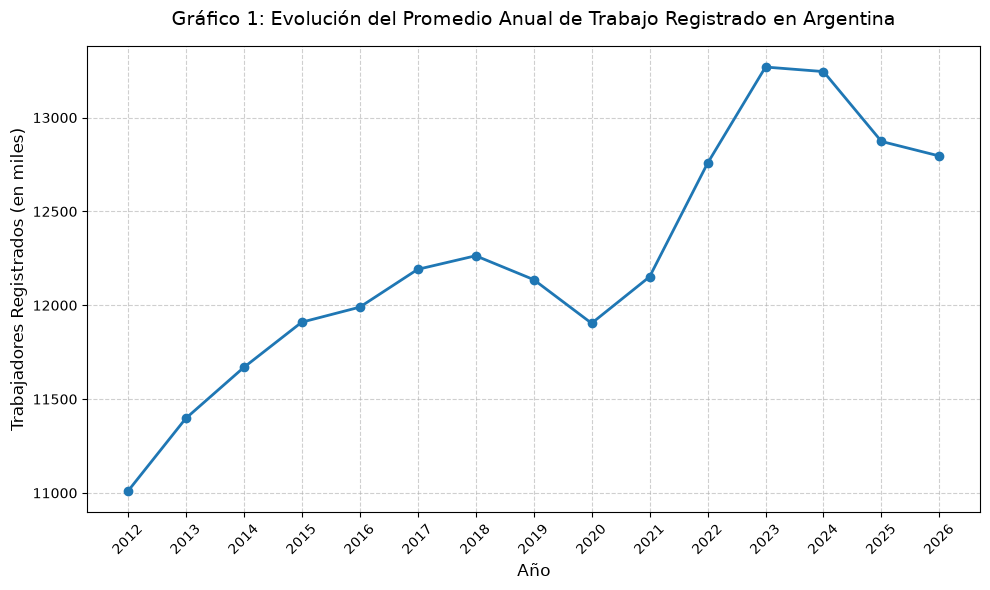

In [18]:
# ==============================================================================
# Gráfico 1
# ==============================================================================

# Leer la pestaña relevante
df = pd.read_excel(ARCHIVO_TRABAJO, sheet_name='T.1', header=2)
# Renombrar columnas
df.columns = [
    'Fecha_Raw',
    'Serie_Original',
    'Serie_Desestacionalizada',
    'Indice_Original',
    'Indice_Desestacionalizado',
    'Volver',
]
# Filtrar filas vacías
df = df.dropna(subset=['Fecha_Raw', 'Serie_Original'])
# Función para extraer el año de forma flexible
def extraer_anio(val):
  if pd.isna(val):
    return None
  if isinstance(val, (pd.Timestamp, datetime)):
    return val.year
  val_str = str(val).strip().lower()
  months = {
      'ene': 1,
      'feb': 2,
      'mar': 3,
      'abr': 4,
      'may': 5,
      'jun': 6,
      'jul': 7,
      'ago': 8,
      'sep': 9,
      'oct': 10,
      'nov': 11,
      'dic': 12,
  }
  for m_name in months:
    if m_name in val_str:
      parts = val_str.replace('*', '').split('-')
      for p in parts:
        p_clean = p.strip()
        if p_clean.isdigit() and len(p_clean) == 2:
          yr = int(p_clean)
          return yr + (2000 if yr < 50 else 1900)
        elif p_clean.isdigit() and len(p_clean) == 4:
          return int(p_clean)
  try:
    return pd.to_datetime(val).year
  except:
    return None
# Extraer el año y calcular el promedio anual
df['Año'] = df['Fecha_Raw'].apply(extraer_anio)
df = df.dropna(subset=['Año'])
df['Año'] = df['Año'].astype(int)
df_anual = df.groupby('Año')['Serie_Original'].mean().reset_index()
# GENERACIÓN DEL GRÁFICO DE LÍNEAS
plt.figure(figsize=(10, 6))
plt.plot(
    df_anual['Año'],
    df_anual['Serie_Original'],
    marker='o',
    color='tab:blue',
    linestyle='-',
    linewidth=2,
)
plt.title(
    'Gráfico 1: Evolución del Promedio Anual de Trabajo Registrado en Argentina',
    fontsize=14,
    pad=15,
)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Trabajadores Registrados (en miles)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_anual['Año'], rotation=45)
plt.tight_layout()
plt.show()

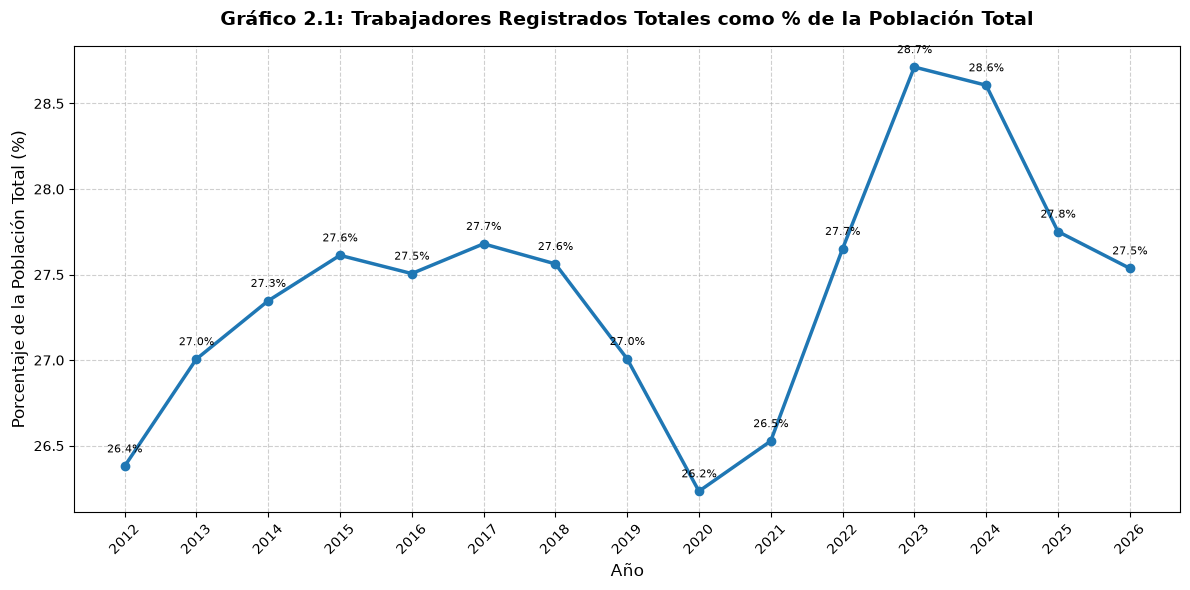

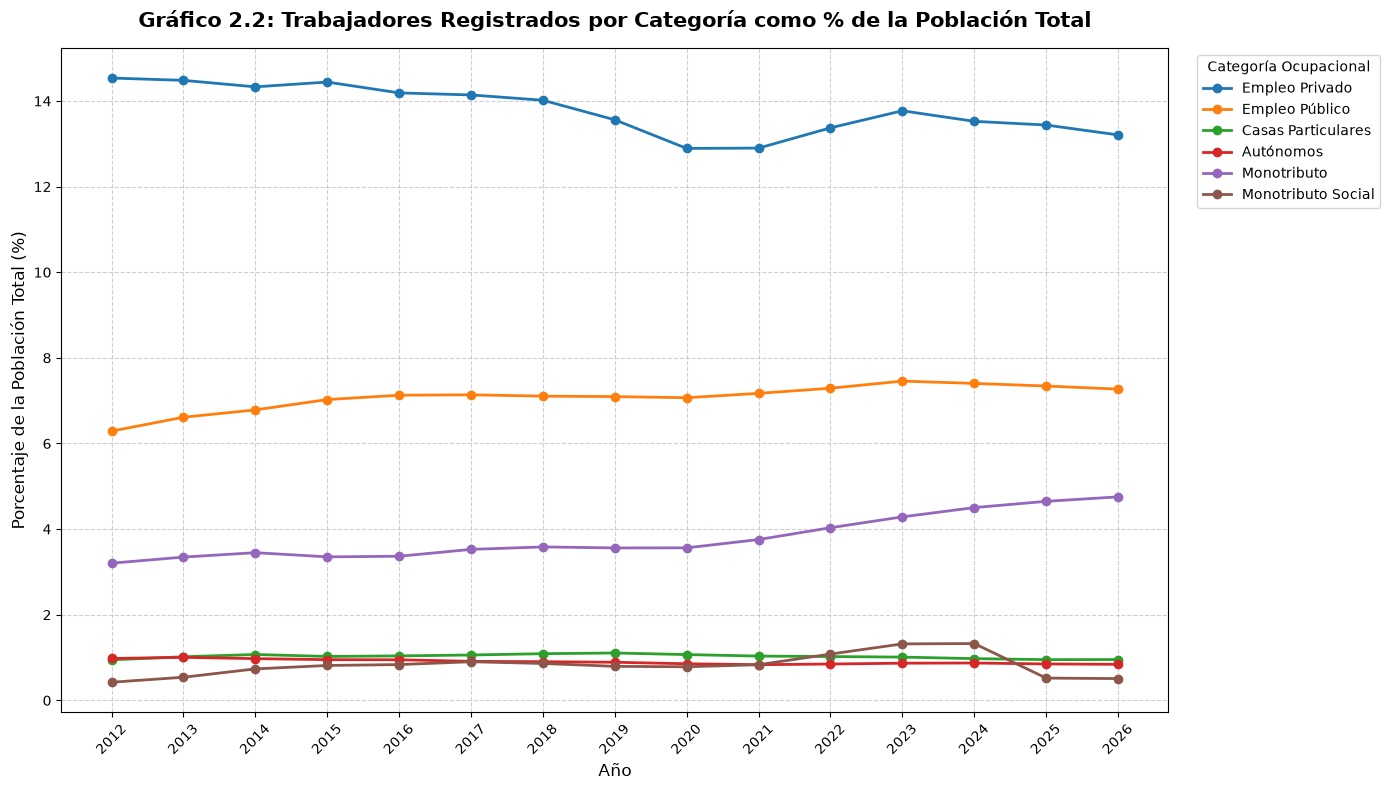

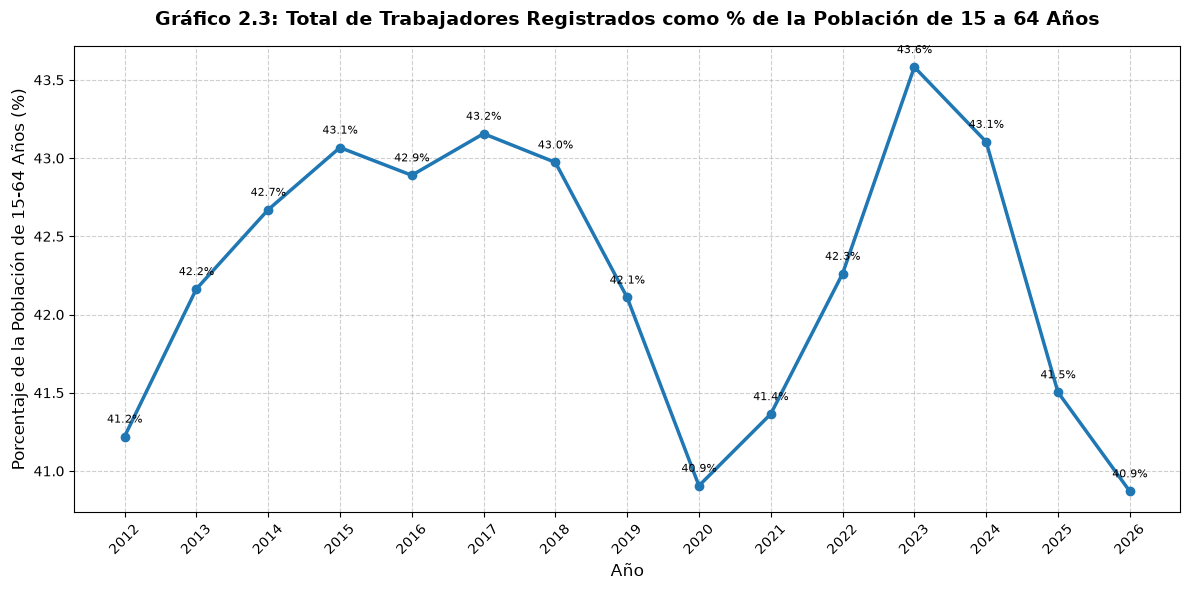

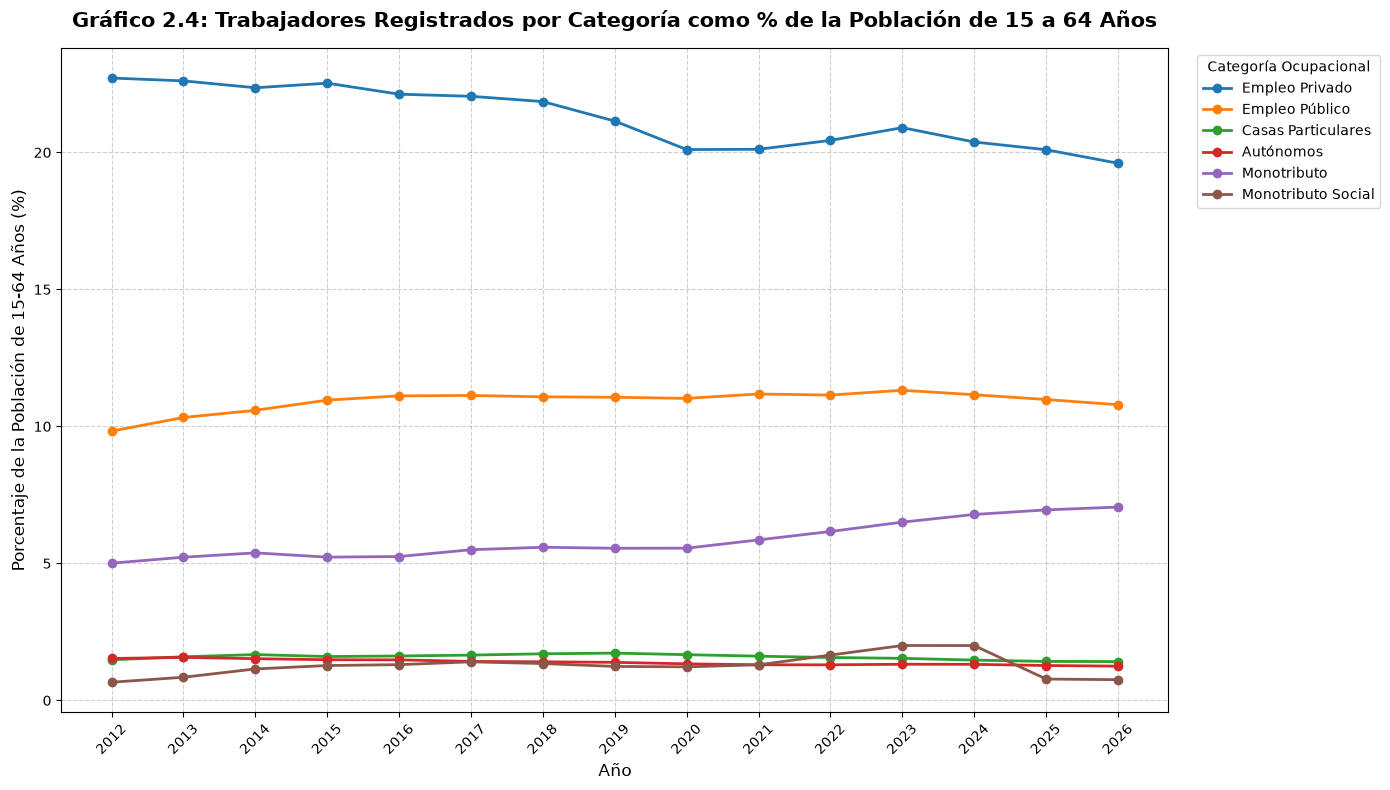

In [19]:
# ==============================================================================
# Gráficos 2
# ==============================================================================

# 1. PROCESAMIENTO DE POBLACIÓN (Total y 15-64 años)
grupos_15_64 = [f"{i}-{i+4}" for i in range(15, 65, 5)]
df_pob_total = (
    df_poblacion_unificada.groupby('Año')['Poblacion']
    .sum()
    .reset_index(name='Poblacion_Total')
)
df_pob_15_64 = (
    df_poblacion_unificada[
        df_poblacion_unificada['Grupo_Edad'].isin(grupos_15_64)
    ]
    .groupby('Año')['Poblacion']
    .sum()
    .reset_index(name='Pob_15_64')
)
# 2. PROCESAMIENTO DE TRABAJO REGISTRADO (Hojas T.1 y T.2.1)
# Hoja T.1 (Totales)
df_t1 = pd.read_excel(ARCHIVO_TRABAJO, sheet_name='T.1', header=2)
df_t1.columns = [
    'Fecha_Raw',
    'Serie_Original',
    'Serie_Desestacionalizada',
    'Indice_Original',
    'Indice_Desestacionalizado',
    'Volver',
][: len(df_t1.columns)]
df_t1 = df_t1.dropna(subset=['Fecha_Raw', 'Serie_Original'])
df_t1['Año'] = df_t1['Fecha_Raw'].apply(extraer_anio)
df_t1_anual = df_t1.groupby('Año')['Serie_Original'].mean().reset_index()
df_t1_anual['Trabajadores_Abs'] = df_t1_anual['Serie_Original'] * 1000
# Hoja T.2.1 (Por categorías)
df_t21 = pd.read_excel(ARCHIVO_TRABAJO, sheet_name='T.2.1', header=1)
df_t21.columns = [
    'Fecha_Raw',
    'Privado',
    'Publico',
    'Casas_Particulares',
    'Autonomos',
    'Monotributo',
    'Monotributo_Social',
    'Total',
    'Extra',
][: len(df_t21.columns)]
df_t21 = df_t21.dropna(subset=['Fecha_Raw', 'Privado'])
df_t21['Año'] = df_t21['Fecha_Raw'].apply(extraer_anio)
categorias = [
    'Privado',
    'Publico',
    'Casas_Particulares',
    'Autonomos',
    'Monotributo',
    'Monotributo_Social',
    'Total',
]
df_t21[categorias] = (
    df_t21[categorias].apply(pd.to_numeric, errors='coerce') * 1000
)
df_t21_anual = df_t21.groupby('Año')[categorias].mean().reset_index()
# 3. CRUCES DE DATOS (Población Total vs. Población 15-64)
df_m_tot = pd.merge(df_pob_total, df_t1_anual, on='Año')
df_m_tot['Porcentaje'] = (
    df_m_tot['Trabajadores_Abs'] / df_m_tot['Poblacion_Total']
) * 100
df_m_tot_cats = pd.merge(df_pob_total, df_t21_anual, on='Año')
cats_, cats_tot = categorias[:-1], categorias[-1]
for c in categorias:
  df_m_tot_cats[f'Pct_{c}'] = (
      df_m_tot_cats[c] / df_m_tot_cats['Poblacion_Total']
  ) * 100
df_m_1564 = pd.merge(df_pob_15_64, df_t21_anual, on='Año')
for c in categorias:
  df_m_1564[f'Pct_{c}'] = (df_m_1564[c] / df_m_1564['Pob_15_64']) * 100
# Estilos comunes
nombres_legibles = {
    'Privado': 'Empleo Privado',
    'Publico': 'Empleo Público',
    'Casas_Particulares': 'Casas Particulares',
    'Autonomos': 'Autónomos',
    'Monotributo': 'Monotributo',
    'Monotributo_Social': 'Monotributo Social',
}
colores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
# Función auxiliar para graficar líneas
def plot_linea(df, x_col, y_col, titulo, ylabel):
  plt.figure(figsize=(12, 6))
  plt.plot(
      df[x_col], df[y_col], marker='o', color='tab:blue', linewidth=2.5
  )
  plt.title(titulo, fontsize=14, fontweight='bold', pad=15)
  plt.xlabel('Año', fontsize=12)
  plt.ylabel(ylabel, fontsize=12)
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.xticks(df[x_col], rotation=45)
  for yr, pct in zip(df[x_col], df[y_col]):
    plt.annotate(
        f'{pct:.1f}%',
        (yr, pct),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center',
        fontsize=8,
    )
  plt.tight_layout()
  plt.show()
def plot_multilineas(df, x_col, cats, titulo, ylabel):
  plt.figure(figsize=(14, 8))
  for cat, col in zip(cats, colores):
    plt.plot(
        df[x_col],
        df[f'Pct_{cat}'],
        marker='o',
        linewidth=2,
        label=nombres_legibles[cat],
        color=col,
    )
  plt.title(titulo, fontsize=15, fontweight='bold', pad=15)
  plt.xlabel('Año', fontsize=12)
  plt.ylabel(ylabel, fontsize=12)
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.xticks(df[x_col], rotation=45)
  plt.legend(
      title='Categoría Ocupacional', bbox_to_anchor=(1.02, 1), loc='upper left'
  )
  plt.tight_layout()
  plt.show()
# 4. GENERACIÓN DE LOS 4 GRÁFICOS
# Gráfico 1: Totales como % de Población Total
plot_linea(
    df_m_tot,
    'Año',
    'Porcentaje',
    'Gráfico 2.1: Trabajadores Registrados Totales como % de la Población Total',
    'Porcentaje de la Población Total (%)',
)
# Gráfico 2: Categorías como % de Población Total
plot_multilineas(
    df_m_tot_cats,
    'Año',
    cats_,
    'Gráfico 2.2: Trabajadores Registrados por Categoría como % de la Población Total',
    'Porcentaje de la Población Total (%)',
)
# Gráfico 3: Totales como % de Población 15-64
plot_linea(
    df_m_1564,
    'Año',
    'Pct_Total',
    'Gráfico 2.3: Total de Trabajadores Registrados como % de la Población de 15 a 64 Años',
    'Porcentaje de la Población de 15-64 Años (%)',
)
# Gráfico 4: Categorías como % de Población 15-64
plot_multilineas(
    df_m_1564,
    'Año',
    cats_,
    'Gráfico 2.4: Trabajadores Registrados por Categoría como % de la Población de 15 a 64 Años',
    'Porcentaje de la Población de 15-64 Años (%)',
)

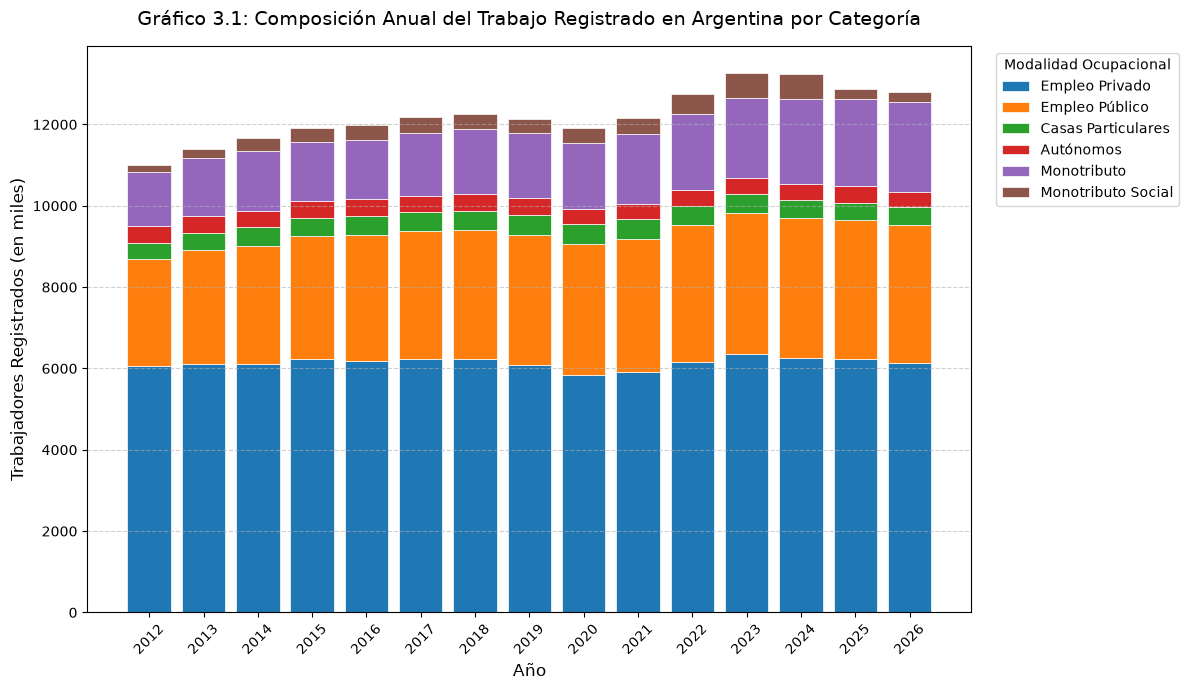

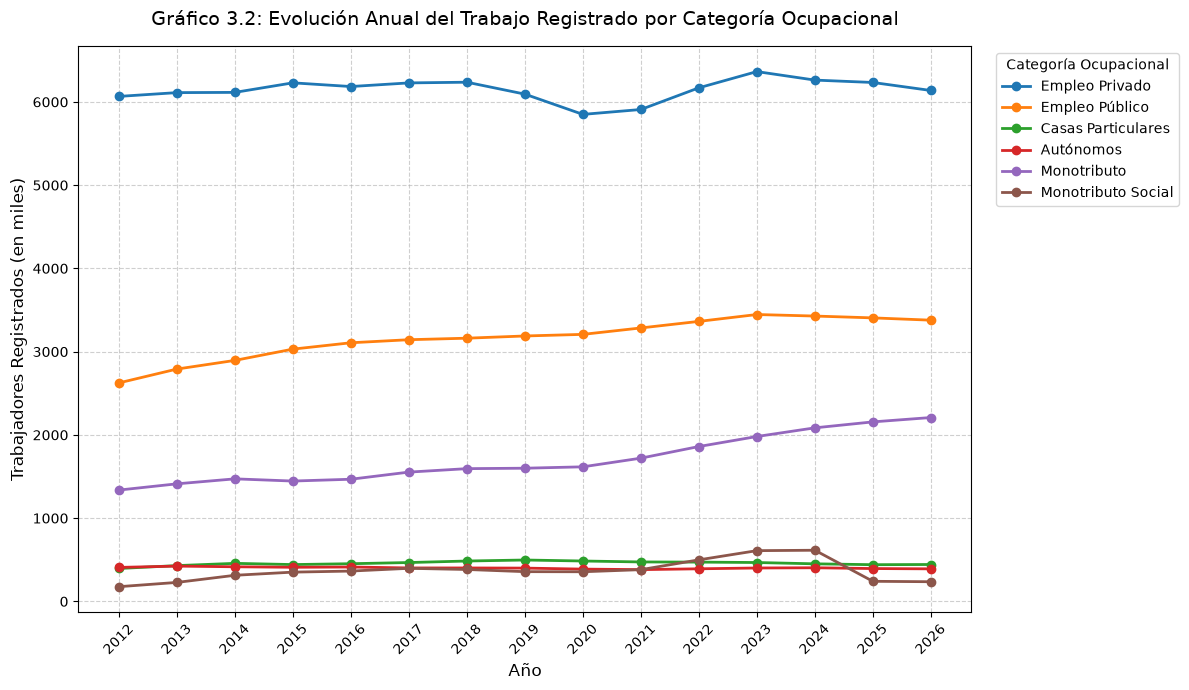

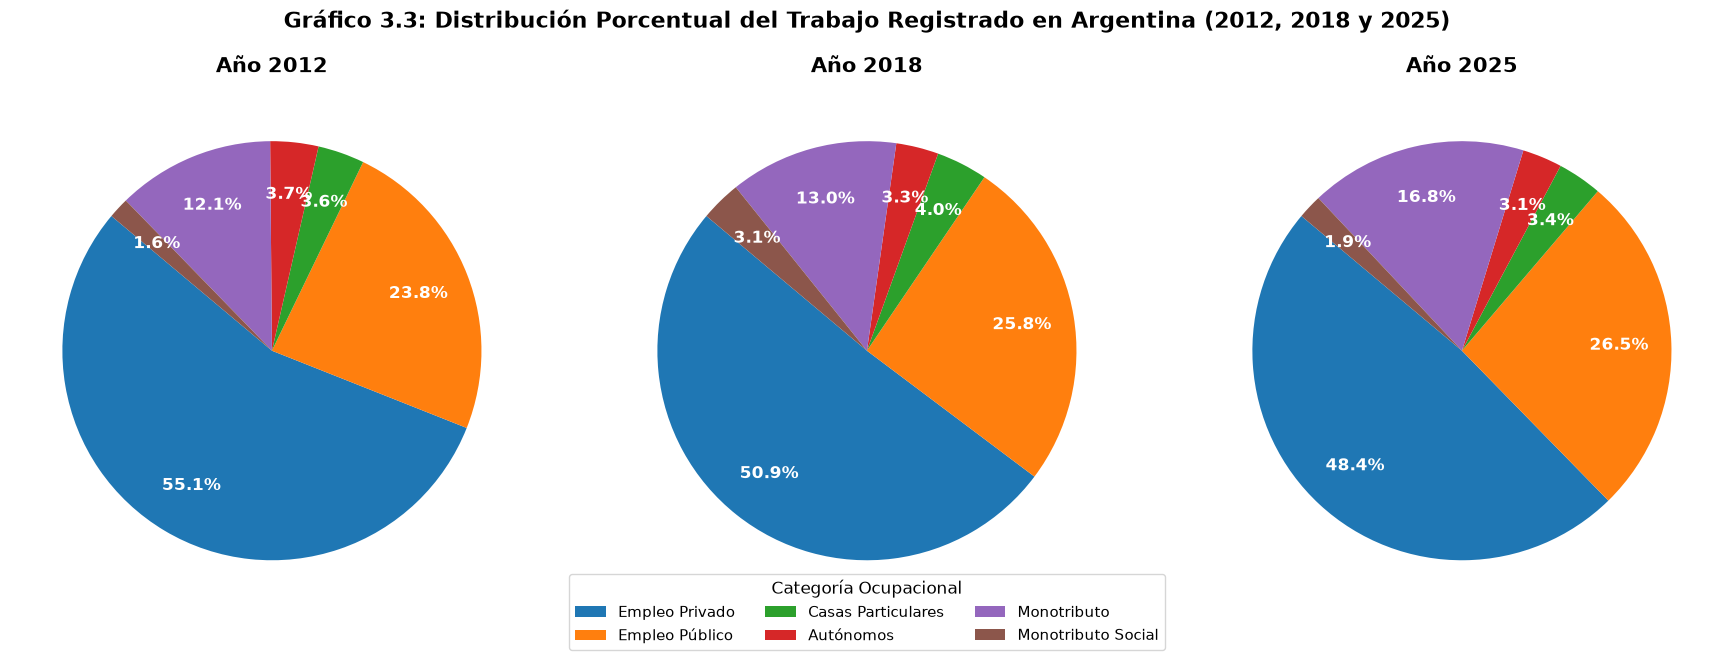

In [20]:
# ==============================================================================
# Gráficos 3
# ==============================================================================

# 1. CARGA Y PROCESAMIENTO DE DATOS (Pestaña T.2.1)
df = pd.read_excel(ARCHIVO_TRABAJO, sheet_name='T.2.1', header=1)
df.columns = [
    'Fecha_Raw',
    'Privado',
    'Publico',
    'Casas_Particulares',
    'Autonomos',
    'Monotributo',
    'Monotributo_Social',
    'Total',
    'Extra',
][: len(df.columns)]
df = df.dropna(subset=['Fecha_Raw', 'Privado'])
def extraer_anio(val):
  if pd.isna(val):
    return None
  if isinstance(val, (pd.Timestamp, datetime)):
    return val.year
  val_str = str(val).strip().lower()
  for m in [
      'ene',
      'feb',
      'mar',
      'abr',
      'may',
      'jun',
      'jul',
      'ago',
      'sep',
      'oct',
      'nov',
      'dic',
  ]:
    if m in val_str:
      parts = [
          p.strip()
          for p in val_str.replace('*', '').split('-')
          if p.strip().isdigit()
      ]
      if parts:
        yr = int(parts[0])
        return yr + (2000 if yr < 50 else 1900) if len(parts[0]) == 2 else yr
  try:
    return pd.to_datetime(val).year
  except:
    return None
df['Año'] = df['Fecha_Raw'].apply(extraer_anio)
df = df.dropna(subset=['Año'])
df['Año'] = df['Año'].astype(int)
categorias = [
    'Privado',
    'Publico',
    'Casas_Particulares',
    'Autonomos',
    'Monotributo',
    'Monotributo_Social',
]
for cat in categorias:
  df[cat] = pd.to_numeric(df[cat], errors='coerce')
# DataFrame anual agrupado (con índice 'Año' y formato estándar)
df_anual = df.groupby('Año')[categorias].mean().reset_index()
# Paleta de colores y nombres legibles comunes
colores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
nombres_legibles = [
    'Empleo Privado',
    'Empleo Público',
    'Casas Particulares',
    'Autónomos',
    'Monotributo',
    'Monotributo Social',
]
anos = df_anual['Año']
# 2. GRÁFICO 1: BARRAS VERTICALES APILADAS
fig, ax = plt.subplots(figsize=(12, 7))
bottom = None
for i, cat in enumerate(categorias):
  valores = df_anual[cat]
  ax.bar(
      anos,
      valores,
      bottom=bottom,
      label=nombres_legibles[i],
      color=colores[i],
      edgecolor='white',
      linewidth=0.5,
  )
  bottom = valores.copy() if bottom is None else bottom + valores
ax.set_title(
    'Gráfico 3.1: Composición Anual del Trabajo Registrado en Argentina por Categoría',
    fontsize=14,
    pad=15,
)
ax.set_xlabel('Año', fontsize=12)
ax.set_ylabel('Trabajadores Registrados (en miles)', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(anos, rotation=45)
ax.legend(title='Modalidad Ocupacional', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
# 3. GRÁFICO 2: LÍNEAS DE EVOLUCIÓN POR CATEGORÍA
plt.figure(figsize=(12, 7))
for i, cat in enumerate(categorias):
  plt.plot(
      anos,
      df_anual[cat],
      marker='o',
      linewidth=2,
      label=nombres_legibles[i],
      color=colores[i],
  )
plt.title(
    'Gráfico 3.2: Evolución Anual del Trabajo Registrado por Categoría Ocupacional',
    fontsize=14,
    pad=15,
)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Trabajadores Registrados (en miles)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(anos, rotation=45)
plt.legend(title='Categoría Ocupacional', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
# 4. GRÁFICO 3: TRES GRÁFICOS CIRCULARES (2012, 2018 y 2025)
ANIOS_A_GRAFICAR = [2012, 2018, 2025]
df_anual_indexed = df_anual.set_index('Año')
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i, anio in enumerate(ANIOS_A_GRAFICAR):
  ax = axes[i]
  if anio in df_anual_indexed.index:
    valores = df_anual_indexed.loc[anio]
    wedges, texts, autotexts = ax.pie(
        valores,
        labels=None,
        autopct='%1.1f%%',
        startangle=140,
        colors=colores,
        pctdistance=0.75,
        textprops=dict(color='white', fontweight='bold', fontsize=12),
    )
    ax.set_title(f'Año {anio}', fontsize=15, fontweight='bold', pad=12)
  else:
    ax.text(
        0.5,
        0.5,
        f'Sin datos para {anio}',
        ha='center',
        va='center',
        transform=ax.transAxes,
        fontsize=12,
    )
fig.legend(
    wedges,
    nombres_legibles,
    title='Categoría Ocupacional',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    fontsize=11,
    title_fontsize=12,
)
plt.suptitle(
    'Gráfico 3.3: Distribución Porcentual del Trabajo Registrado en Argentina (2012, 2018'
    ' y 2025)',
    fontsize=16,
    fontweight='bold',
    y=1.03,
)
plt.tight_layout()
plt.show()

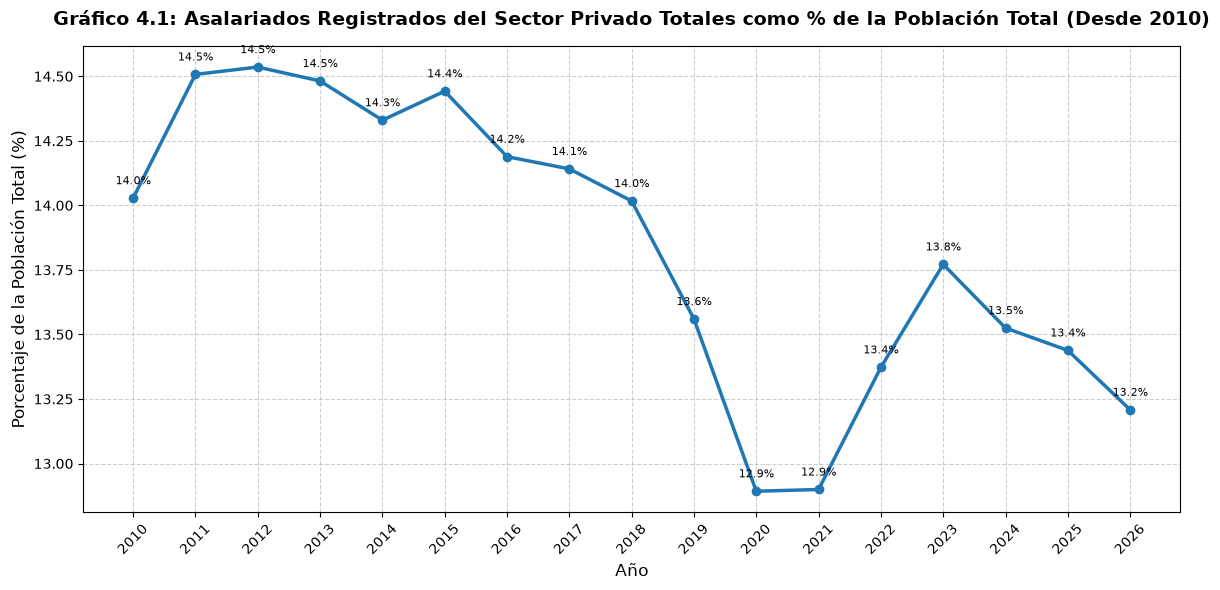

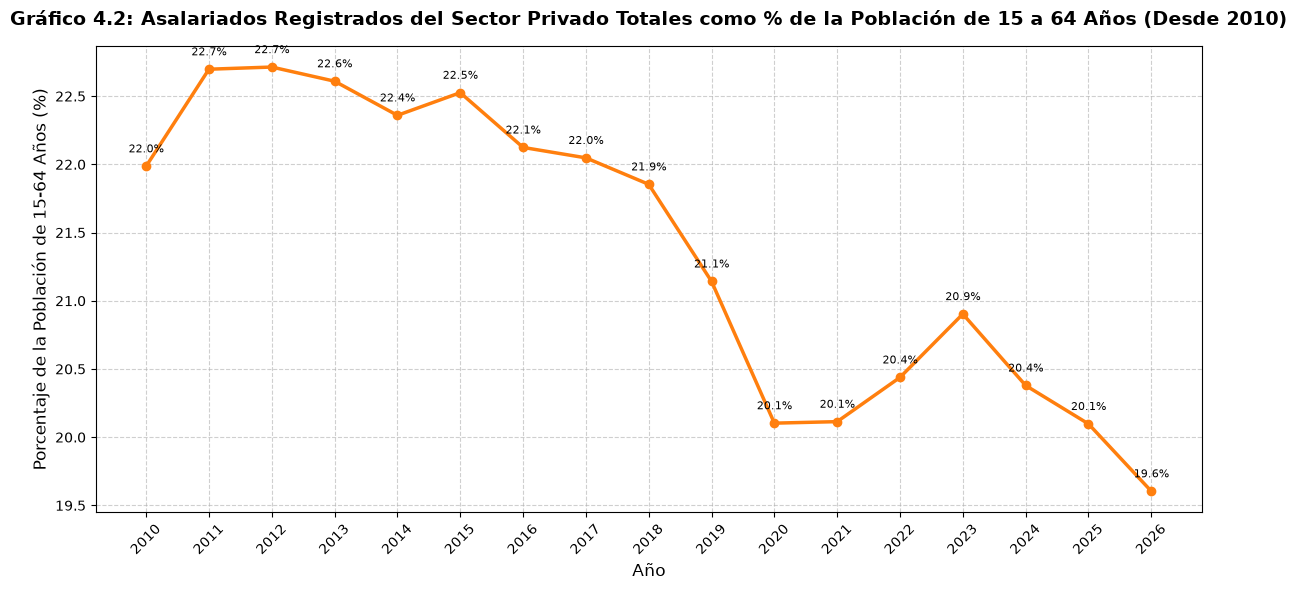

In [21]:
# ==============================================================================
# Gráficos 4
# ==============================================================================

# 1. PREPARACIÓN DE DENOMINADORES DEMOGRÁFICOS (Población Total y 15-64 años)
grupos_15_64 = [f'{i}-{i+4}' for i in range(15, 65, 5)]
df_pob_total = (
    df_poblacion_unificada.groupby('Año')['Poblacion']
    .sum()
    .reset_index(name='Poblacion_Total')
)
df_pob_15_64 = (
    df_poblacion_unificada[
        df_poblacion_unificada['Grupo_Edad'].isin(grupos_15_64)
    ]
    .groupby('Año')['Poblacion']
    .sum()
    .reset_index(name='Pob_15_64')
)
# 2. PROCESAMIENTO DE TRABAJO ASALARIADO REGISTRADO (Pestaña A.1)
excel_trabajo = pd.ExcelFile(ARCHIVO_TRABAJO)
df_a1 = pd.read_excel(excel_trabajo, sheet_name='A.1', header=2)
df_a1.columns = [
    'Fecha_Raw',
    'Serie_Original',
    'Serie_Desestacionalizada',
    'Indice_Original',
    'Indice_Desestacionalizado',
    'Volver',
][: len(df_a1.columns)]
df_a1 = df_a1.dropna(subset=['Fecha_Raw', 'Serie_Original'])
df_a1['Año'] = df_a1['Fecha_Raw'].apply(extraer_anio)
df_a1_anual = df_a1.groupby('Año')['Serie_Original'].mean().reset_index()
df_a1_anual['Trabajadores_Abs'] = df_a1_anual['Serie_Original'] * 1000
# 3. CRUCES Y CÁLCULOS PORCENTUALES
df_m_tot = pd.merge(df_pob_total, df_a1_anual, on='Año', how='inner')
df_m_tot['Pct_Total'] = (
    df_m_tot['Trabajadores_Abs'] / df_m_tot['Poblacion_Total']
) * 100
df_m_1564 = pd.merge(df_pob_15_64, df_a1_anual, on='Año', how='inner')
df_m_1564['Pct_1564'] = (
    df_m_1564['Trabajadores_Abs'] / df_m_1564['Pob_15_64']
) * 100
# 4. GENERACIÓN DE LOS 2 GRÁFICOS DE LÍNEAS
# Gráfico 1: Asalariados Registrados como % de la Población Total (desde 2009)
plt.figure(figsize=(12, 6))
plt.plot(
    df_m_tot['Año'],
    df_m_tot['Pct_Total'],
    marker='o',
    color='tab:blue',
    linewidth=2.5,
    markersize=6,
)
plt.title(
    'Gráfico 4.1: Asalariados Registrados del Sector Privado Totales como % de la Población Total (Desde 2010)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Porcentaje de la Población Total (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_m_tot['Año'], rotation=45)
for yr, pct in zip(df_m_tot['Año'], df_m_tot['Pct_Total']):
  plt.annotate(
      f'{pct:.1f}%',
      (yr, pct),
      textcoords='offset points',
      xytext=(0, 10),
      ha='center',
      fontsize=8,
  )
plt.tight_layout()
plt.show()
# Gráfico 2: Asalariados Registrados como % de la Población de 15 a 64 años (desde 2009)
plt.figure(figsize=(12, 6))
plt.plot(
    df_m_1564['Año'],
    df_m_1564['Pct_1564'],
    marker='o',
    color='tab:orange',
    linewidth=2.5,
    markersize=6,
)
plt.title(
    'Gráfico 4.2: Asalariados Registrados del Sector Privado Totales como % de la Población de 15 a 64 Años'
    ' (Desde 2010)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Porcentaje de la Población de 15-64 Años (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_m_1564['Año'], rotation=45)
for yr, pct in zip(df_m_1564['Año'], df_m_1564['Pct_1564']):
  plt.annotate(
      f'{pct:.1f}%',
      (yr, pct),
      textcoords='offset points',
      xytext=(0, 10),
      ha='center',
      fontsize=8,
  )
plt.tight_layout()
plt.show()

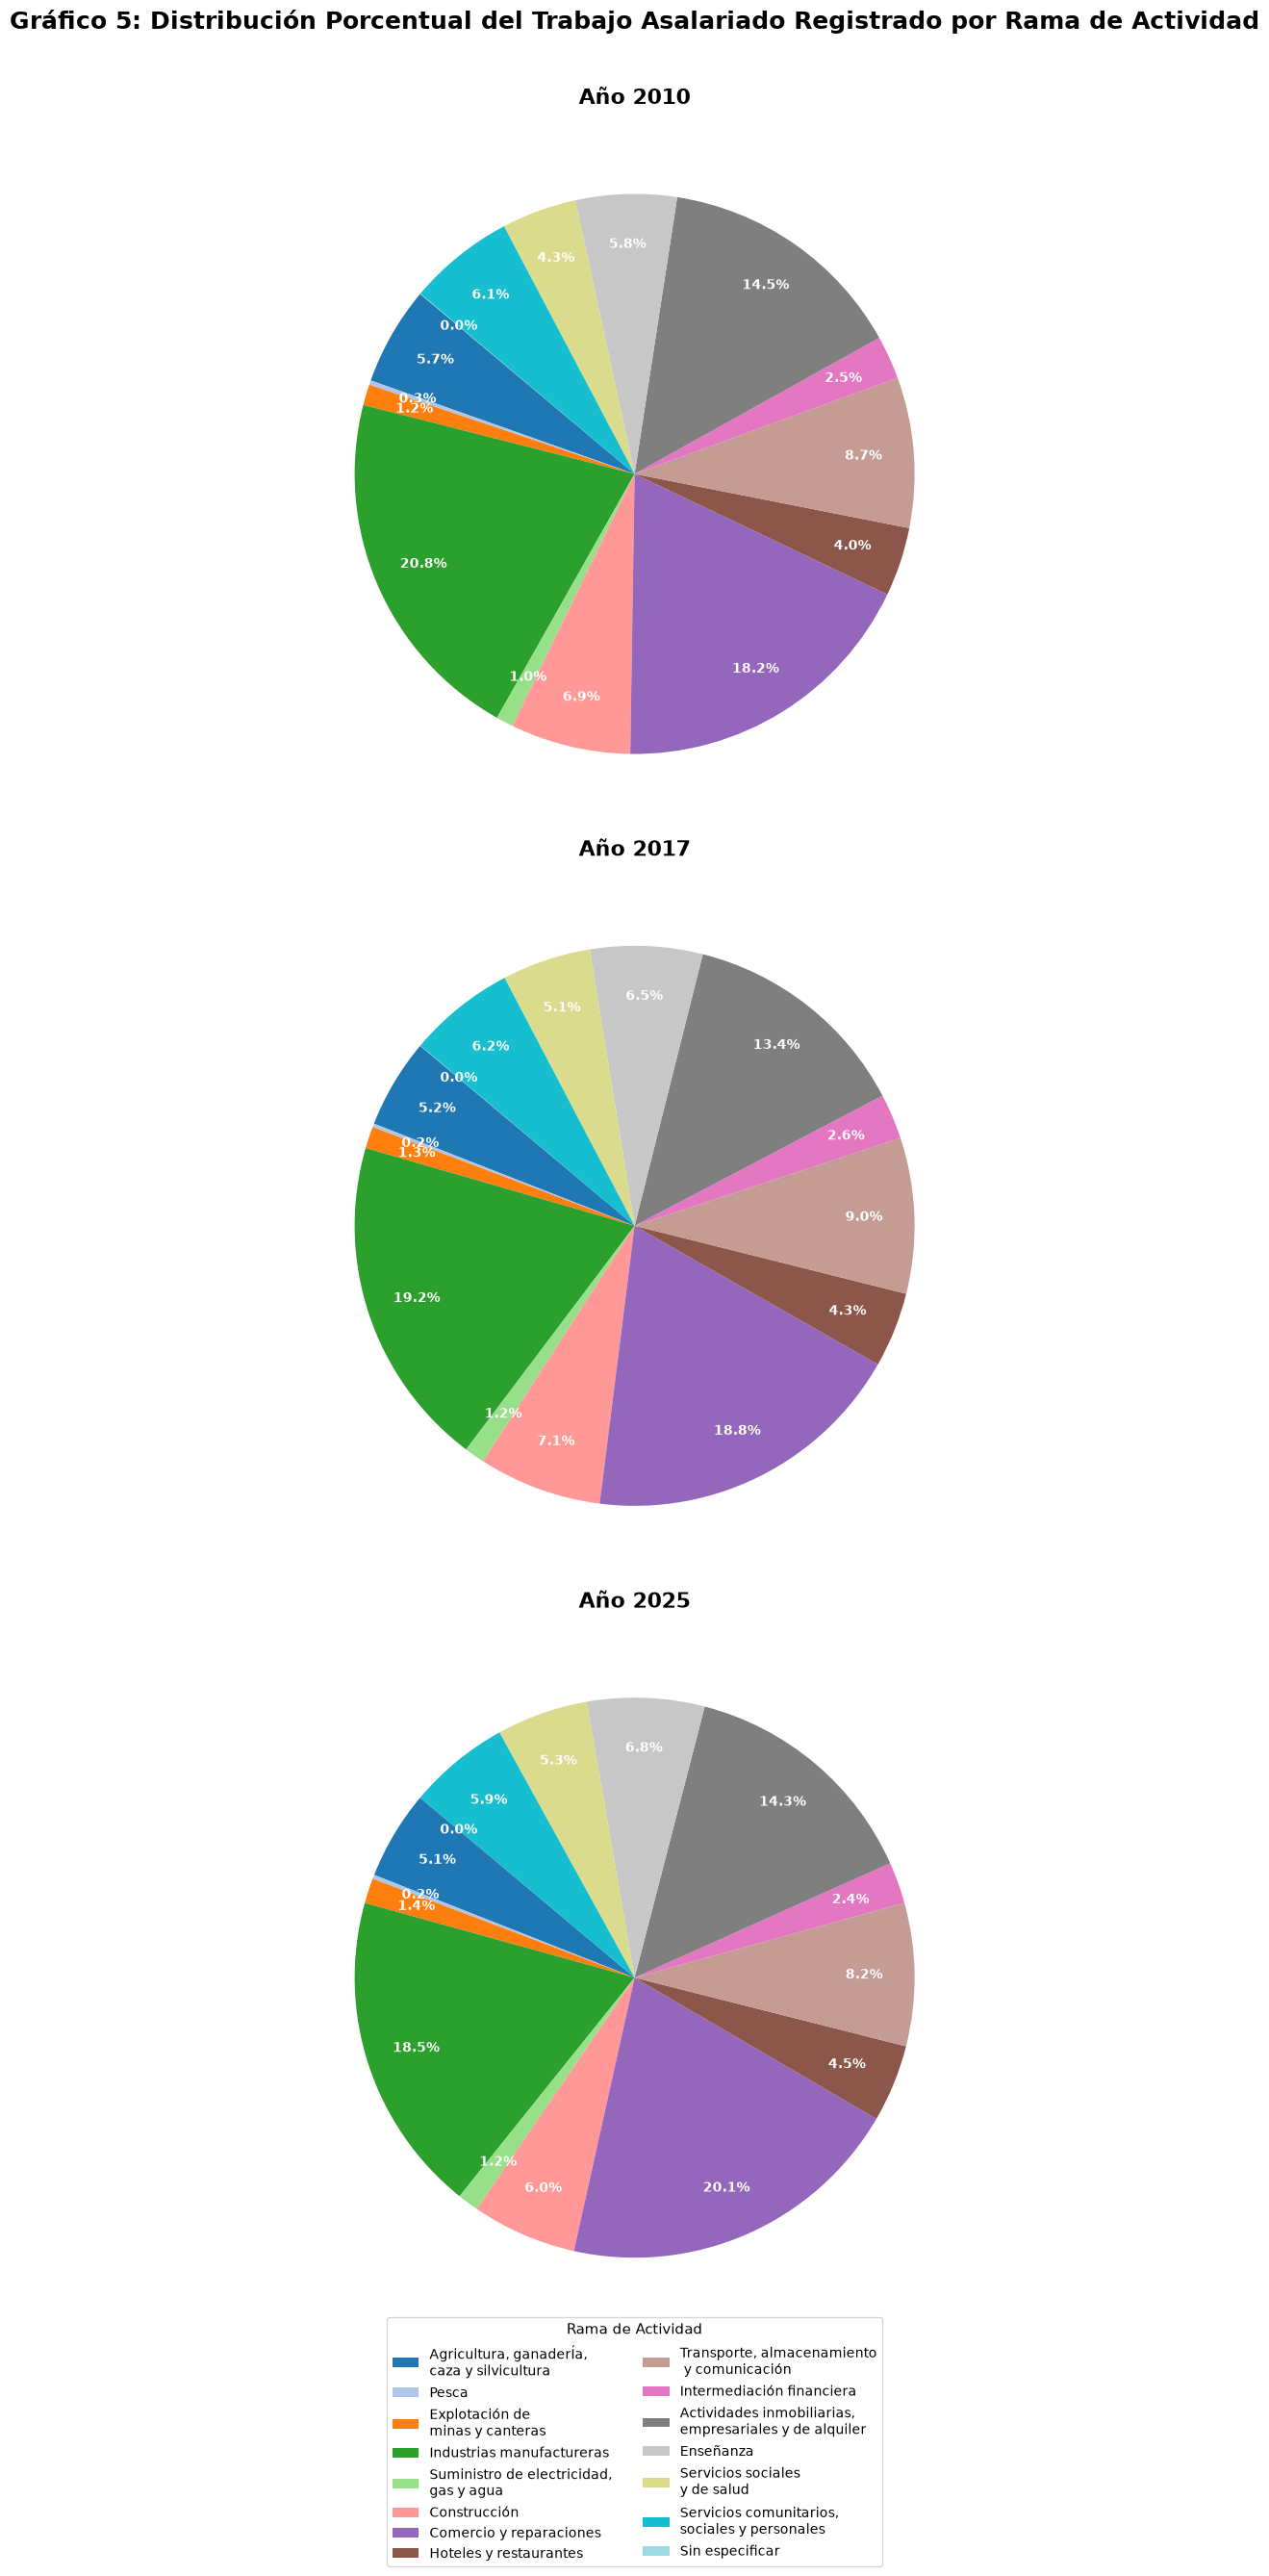

In [25]:
# ==============================================================================
# Gráfico 5
# ==============================================================================

# CARGA Y EXTRACCIÓN ROBUSTA 
excel_trabajo = pd.ExcelFile(ARCHIVO_TRABAJO)
df_a21_raw = pd.read_excel(excel_trabajo, sheet_name='A.2.1', header=None)
nombres_ramas_b_p = df_a21_raw.iloc[1, 1:16].values
df_a21 = df_a21_raw.iloc[2:].copy()
df_a21.columns = ['Periodo'] + list(nombres_ramas_b_p) + [
    f'Extra_{i}' for i in range(16, len(df_a21.columns))
]
df_a21 = df_a21.dropna(subset=['Periodo'])
def extraer_anio(val):
  try:
    if pd.isna(val):
      return np.nan
    # Si es un objeto datetime de Python (ej: 2009-01-01)
    if isinstance(val, (datetime, pd.Timestamp)):
      return val.year
    val_str = str(val).strip()
    # Si es una fila de texto institucional / nota al pie, descartarla
    if any(
        x in val_str.lower()
        for x in ['nota', 'fuente', '*', 'provisorio', 'el empleo']
    ):
      return np.nan
    # Buscar explícitamente un año de 4 dígitos (ej: 2017, 2025)
    match_4dig = re.search(r'(19\d{2}|20\d{2})', val_str)
    if match_4dig:
      return int(match_4dig.group(1))
    # Si viene en formato tipo 'feb-15', 'ene-26', etc.
    match_2dig = re.search(r'[a-zA-Z]{3}-(\d{2})', val_str)
    if match_2dig:
      yy = int(match_2dig.group(1))
      # Si yy es menor a 50 asumimos 2000+, si no 1900+
      return 2000 + yy if yy < 50 else 1900 + yy
    return np.nan
  except:
    return np.nan
df_a21['Año'] = df_a21['Periodo'].apply(extraer_anio)
df_a21 = df_a21.dropna(subset=['Año'])
df_a21['Año'] = df_a21['Año'].astype(int)
ramas_cols = list(nombres_ramas_b_p)
for col in ramas_cols:
  df_a21[col] = pd.to_numeric(df_a21[col], errors='coerce')
df_a21_anual = (
    df_a21.groupby('Año')[ramas_cols].mean().reset_index().set_index('Año')
)
# GENERACIÓN DE LOS 3 GRÁFICOS CIRCULARES VERTICALES (2010, 2017 y 2025)
ANIOS_RAMAS = [2010, 2017, 2025]
fig, axes = plt.subplots(3, 1, figsize=(10, 24))
colores_ramas = cm.tab20(np.linspace(0, 1, len(ramas_cols)))
wedges = None
anos_ya_usados = []
for i, anio_objetivo in enumerate(ANIOS_RAMAS):
  ax = axes[i]
  candidatos = [a for a in df_a21_anual.index if a not in anos_ya_usados]
  if not candidatos:
    candidatos = list(df_a21_anual.index)
  anio_a_usar = min(candidatos, key=lambda x: abs(x - anio_objetivo))
  anos_ya_usados.append(anio_a_usar)
  if anio_a_usar in df_a21_anual.index:
    valores = df_a21_anual.loc[anio_a_usar].dropna()
    valores = valores[valores > 0]
    wedges, texts, autotexts = ax.pie(
        valores,
        labels=None,
        autopct='%1.1f%%',
        startangle=140,
        colors=colores_ramas[: len(valores)],
        pctdistance=0.82,
        textprops=dict(color='white', fontweight='bold', fontsize=10),
    )
    ax.set_title(
        f'Año {anio_a_usar}', fontsize=16, fontweight='bold', pad=15
    )
  else:
    ax.text(
        0.5,
        0.5,
        f'Sin datos para {anio_objetivo}',
        ha='center',
        va='center',
        transform=ax.transAxes,
        fontsize=14,
    )
# Leyenda unificada abajo
if wedges is not None:
  fig.legend(
      wedges,
      ramas_cols[: len(wedges)],
      title='Rama de Actividad',
      loc='lower center',
      bbox_to_anchor=(0.5, -0.10),
      ncol=2,
      fontsize=10,
      title_fontsize=11,
  )
plt.suptitle(
    'Gráfico 5: Distribución Porcentual del Trabajo Asalariado Registrado por Rama de'
    ' Actividad',
    fontsize=18,
    fontweight='bold',
    y=1.01,
)
plt.tight_layout()
plt.show()

In [26]:
# ==============================================================================
# Tabla 1
# ==============================================================================

# CARGA CORRECTA DE LA PESTAÑA A.5.1 (Valores absolutos directos)
excel_trabajo = pd.ExcelFile(ARCHIVO_TRABAJO)
def extraer_anio(val):
  try:
    if pd.isna(val):
      return np.nan
    val_str = str(val).strip()
    if any(
        x in val_str.lower()
        for x in ['nota', 'fuente', '*', 'provisorio', 'el empleo']
    ):
      return np.nan
    match = re.search(r'(19\d{2}|20\d{2})', val_str)
    if match:
      return int(match.group(1))
    match_2d = re.search(r'[a-zA-Z]{3}-(\d{2})', val_str)
    if match_2d:
      yy = int(match_2d.group(1))
      return 2000 + yy if yy < 50 else 1900 + yy
    return np.nan
  except:
    return np.nan
# Leer la pestaña A.5.1 en bruto
df_a51_raw = pd.read_excel(excel_trabajo, sheet_name='A.5.1', header=None)
# Las provincias están desde la columna B hasta la Y (índices 1 a 24 en la fila 2 / índice 1)
nombres_provs_b_y = df_a51_raw.iloc[1, 1:25].values
# Los datos comienzan en la fila 3 (índice 2)
df_a51 = df_a51_raw.iloc[2:].copy()
df_a51.columns = ['Periodo'] + list(nombres_provs_b_y) + [
    f'Extra_{i}' for i in range(25, len(df_a51.columns))
]
df_a51 = df_a51.dropna(subset=['Periodo'])
df_a51['Año'] = df_a51['Periodo'].apply(extraer_anio)
df_a51 = df_a51.dropna(subset=['Año'])
df_a51['Año'] = df_a51['Año'].astype(int)
prov_cols = list(nombres_provs_b_y)
for c in prov_cols:
  df_a51[c] = pd.to_numeric(df_a51[c], errors='coerce')
# Promedio anual de trabajadores registrados por provincia
a51_anual = df_a51.groupby('Año')[prov_cols].mean()
# CÁLCULO DE PORCENTAJES (Sobre la suma total de las provincias de cada año)
anios_tabla = [2009, 2017, 2025]
resultado = {}
for prov in prov_cols:
  nombre_prov = str(prov).split('/')[0].strip()
  res_prov = {}
  for anio in anios_tabla:
    if anio in a51_anual.index:
      fila_anio = a51_anual.loc[anio]
      val_prov = fila_anio[prov]
      total_provincias = fila_anio[
          prov_cols
      ].sum()  # Suma de todas las jurisdicciones
      if pd.notna(val_prov) and total_provincias > 0:
        # Porcentaje exacto de la provincia respecto al total provincial
        res_prov[f'{anio}'] = (val_prov / total_provincias) * 100
      else:
        res_prov[f'{anio}'] = np.nan
    else:
      res_prov[f'{anio}'] = np.nan
  resultado[nombre_prov] = res_prov
# Crear DataFrame
df_tabla = pd.DataFrame(resultado).T
# Ordenar estrictamente de mayor a menor según el año 2009
df_tabla = df_tabla.sort_values(by='2009', ascending=False)
# Formatear celdas con 2 decimales y símbolo %
df_tabla_format = df_tabla.map(
    lambda x: f'{x:.2f}%' if pd.notna(x) else 'Sin datos'
)
# MOSTRAR TÍTULO Y TABLA EN JUPYTER
display(
    HTML(
        '<h4>Tabla 1: porcentaje del total de trabajadores asalariados'
        ' registrados del sector privado que corresponde a cada provincia.</h4>'
    )
)
display(df_tabla_format)

,2009,2017,2025
BUENOS AIRES,31.18%,31.46%,31.60%
Cdad. Autónoma \nde Buenos Aires,26.08%,24.81%,24.13%
SANTA FE,8.09%,8.14%,8.17%
CÓRDOBA,8.08%,8.19%,8.34%
MENDOZA,3.93%,3.92%,3.95%
TUCUMÁN,2.67%,2.69%,2.59%
ENTRE RÍOS,2.20%,2.19%,2.18%
SALTA,1.81%,1.88%,1.96%
RíO NEGRO,1.68%,1.68%,1.78%
CHUBUT,1.62%,1.56%,1.50%


C:\Users\outlet\AppData\Local\Temp\ipykernel_14288\3680224331.py:6: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df_pbi_raw = pd.read_excel(ARCHIVO_PBI, sheet_name='cuadro 1', header=None)


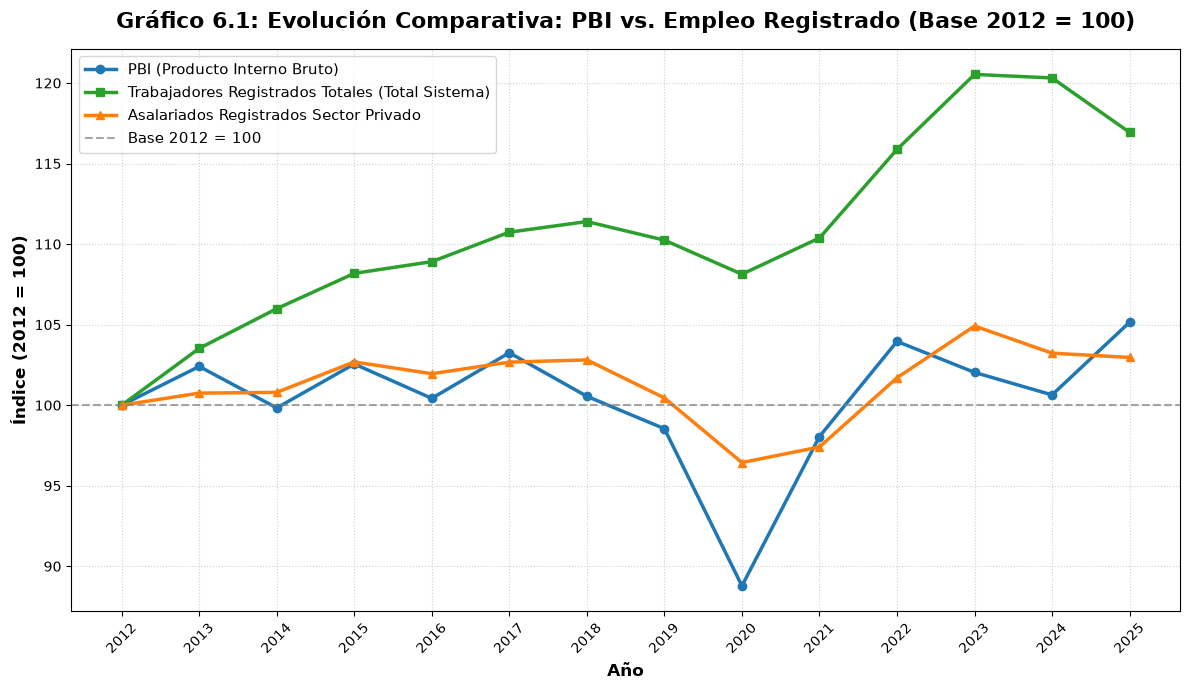

 TABLA 2: CRECIMIENTO Y ELASTICIDAD (ASALARIADOS PRIVADOS / PBI) 
      PBI (Nivel)  Empleo Privado (Nivel)  Var. % PBI  Var. % Empleo Privado  Elasticidad Anual
Año                                                                                            
2012   703,485.99                6,066.27         NaN                    NaN                NaN
2013   720,407.11                6,111.76        2.41                   0.75               0.31
2014   702,306.05                6,114.56       -2.51                   0.05              -0.02
2015   721,487.15                6,229.26        2.73                   1.88               0.69
2016   706,477.85                6,184.87       -2.08                  -0.71               0.34
2017   726,389.95                6,228.47        2.82                   0.70               0.25
2018   707,377.44                6,236.79       -2.62                   0.13              -0.05
2019   693,223.80                6,093.66       -2.00                 

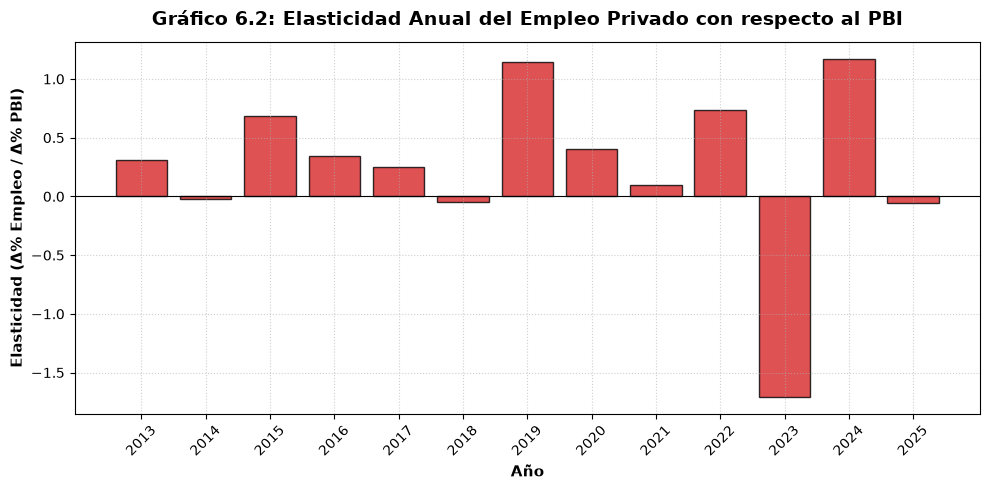

In [29]:
# ==============================================================================
# Gráficos 6 y tabla 2
# ==============================================================================

# 1. EXTRACCIÓN DEL PBI (Pestaña 'cuadro 1' de sh_oferta_demanda_09_26.xls)
df_pbi_raw = pd.read_excel(ARCHIVO_PBI, sheet_name='cuadro 1', header=None)
anios_pbi = []
valores_pbi = []
current_year = None
for col in range(df_pbi_raw.shape[1]):
  val_row3 = df_pbi_raw.iloc[3, col]
  if pd.notna(val_row3):
    match = re.search(r'\d{4}', str(val_row3))
    if match:
      current_year = int(match.group(0))
  val_row4 = df_pbi_raw.iloc[4, col]
  if pd.notna(val_row4) and str(val_row4).strip() == 'Total':
    if current_year is not None:
      pbi_val = df_pbi_raw.iloc[6, col]
      anios_pbi.append(current_year)
      valores_pbi.append(pbi_val)
df_pbi = pd.DataFrame({'Año': anios_pbi, 'PBI': valores_pbi})
df_pbi_anual = df_pbi.groupby('Año')['PBI'].mean()
# 2. EXTRACCIÓN DE EMPLEO REGISTRADO 
excel_empleo = pd.ExcelFile(ARCHIVO_TRABAJO)
def extraer_anio(val):
  try:
    if pd.isna(val):
      return np.nan
    val_str = str(val).strip()
    if any(
        x in val_str.lower()
        for x in ['nota', 'fuente', '*', 'provisorio', 'el empleo']
    ):
      return np.nan
    match = re.search(r'(19\d{2}|20\d{2})', val_str)
    if match:
      return int(match.group(1))
    match_2d = re.search(r'[a-zA-Z]{3}-(\d{2})', val_str)
    if match_2d:
      yy = int(match_2d.group(1))
      return 2000 + yy if yy < 50 else 1900 + yy
    return np.nan
  except:
    return np.nan
# A. Asalariados Registrados del Sector Privado (Pestaña A.1)
df_a1 = pd.read_excel(excel_empleo, sheet_name='A.1', header=2)
df_a1['Año'] = df_a1[df_a1.columns[0]].apply(extraer_anio)
df_a1 = df_a1.dropna(subset=['Año'])
df_a1['Año'] = df_a1['Año'].astype(int)
col_privado = df_a1.columns[1]
df_a1[col_privado] = pd.to_numeric(df_a1[col_privado], errors='coerce')
emp_privado_anual = df_a1.groupby('Año')[col_privado].mean()
# B. Trabajadores Registrados Totales (Pestaña T.1- Total general del sistema)
df_a3 = pd.read_excel(excel_empleo, sheet_name='T.1', header=2)
df_a3['Año'] = df_a3[df_a3.columns[0]].apply(extraer_anio)
df_a3 = df_a3.dropna(subset=['Año'])
df_a3['Año'] = df_a3['Año'].astype(int)
col_total = df_a3.columns[1]
df_a3[col_total] = pd.to_numeric(df_a3[col_total], errors='coerce')
emp_total_anual = df_a3.groupby('Año')[col_total].mean()
# 3. UNIFICACIÓN DE DATOS A PARTIR DE 2012 Y CONSTRUCCIÓN DE ÍNDICES (2012 = 100)
df_merged = (
    pd.DataFrame({
        'PBI': df_pbi_anual,
        'Trabajadores_Registrados_Totales': emp_total_anual,
        'Asalariados_Privados': emp_privado_anual,
    })
    .loc[2012:]
    .dropna(how='all')
)
# Convertir cada columna a Base 100 en el año 2012
df_index = pd.DataFrame(index=df_merged.index)
for col in df_merged.columns:
  val_base_2012 = df_merged.loc[2012, col]
  df_index[col] = (df_merged[col] / val_base_2012) * 100
# 4. GRÁFICO DE LÍNEAS CORREGIDO
plt.figure(figsize=(12, 7))
plt.plot(
    df_index.index,
    df_index['PBI'],
    marker='o',
    linewidth=2.5,
    color='#1f77b4',
    label='PBI (Producto Interno Bruto)',
)
plt.plot(
    df_index.index,
    df_index['Trabajadores_Registrados_Totales'],
    marker='s',
    linewidth=2.5,
    color='#2ca02c',
    label='Trabajadores Registrados Totales (Total Sistema)',
)
plt.plot(
    df_index.index,
    df_index['Asalariados_Privados'],
    marker='^',
    linewidth=2.5,
    color='#ff7f0e',
    label='Asalariados Registrados Sector Privado',
)
# Línea de referencia en 100 (Año 2012)
plt.axhline(100, color='gray', linestyle='--', alpha=0.7, label='Base 2012 = 100')
plt.title(
    'Gráfico 6.1: Evolución Comparativa: PBI vs. Empleo Registrado (Base 2012 = 100)',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Año', fontsize=12, fontweight='bold')
plt.ylabel('Índice (2012 = 100)', fontsize=12, fontweight='bold')
plt.xticks(df_index.index, rotation=45)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='best')
plt.tight_layout()
plt.show()
# 5. CÁLCULO DE LA ELASTICIDAD DEL EMPLEO PRIVADO CON RESPECTO AL PBI
# Calcular las variaciones porcentuales anuales
df_merged['Var_Pct_PBI'] = df_merged['PBI'].pct_change() * 100
df_merged['Var_Pct_Privados'] = (
    df_merged['Asalariados_Privados'].pct_change() * 100
)
# Elasticidad anual puntual (Var. % Empleo Privado / Var. % PBI)
df_merged['Elasticidad_Anual'] = (
    df_merged['Var_Pct_Privados'] / df_merged['Var_Pct_PBI']
)
# Elasticidad acumulada total desde 2012 hasta el último año disponible
pbi_inicial = df_merged.loc[2012, 'PBI']
pbi_final = df_merged.loc[df_merged.index[-1], 'PBI']
priv_inicial = df_merged.loc[2012, 'Asalariados_Privados']
priv_final = df_merged.loc[df_merged.index[-1], 'Asalariados_Privados']
var_acum_pbi = ((pbi_final / pbi_inicial) - 1) * 100
var_acum_privados = ((priv_final / priv_inicial) - 1) * 100
elasticidad_acumulada = var_acum_privados / var_acum_pbi
# Mostrar resultados en la consola
print('=' * 80)
print(
    ' TABLA 2: CRECIMIENTO Y ELASTICIDAD (ASALARIADOS PRIVADOS / PBI) '
)
print('=' * 80)
tabla_elasticidad = df_merged[
    [
        'PBI',
        'Asalariados_Privados',
        'Var_Pct_PBI',
        'Var_Pct_Privados',
        'Elasticidad_Anual',
    ]
].copy()
tabla_elasticidad.columns = [
    'PBI (Nivel)',
    'Empleo Privado (Nivel)',
    'Var. % PBI',
    'Var. % Empleo Privado',
    'Elasticidad Anual',
]
print(tabla_elasticidad.to_string(float_format=lambda x: f'{x:,.2f}'))
print('=' * 80)
print(
    f'📊 Variación Acumulada PBI (2012-{df_merged.index[-1]}):'
    f' {var_acum_pbi:.2f}%'
)
print(
    f'📊 Variación Acumulada Empleo Privado (2012-{df_merged.index[-1]}):'
    f' {var_acum_privados:.2f}%'
)
print(
    f'🔗 Elasticidad Acumulada Total (Periodo 2012-{df_merged.index[-1]}):'
    f' {elasticidad_acumulada:.4f}'
)
print('=' * 80)

# Opcional: Gráfico de barras con la elasticidad anual
plt.figure(figsize=(10, 5))
plt.bar(
    df_merged.index[1:],
    df_merged['Elasticidad_Anual'].iloc[1:],
    color='#d62728',
    alpha=0.8,
    edgecolor='black',
)
plt.axhline(0, color='black', linestyle='-', linewidth=0.8)
plt.title(
    'Gráfico 6.2: Elasticidad Anual del Empleo Privado con respecto al PBI',
    fontsize=14,
    fontweight='bold',
    pad=12,
)
plt.xlabel('Año', fontsize=11, fontweight='bold')
plt.ylabel('Elasticidad (Δ% Empleo / Δ% PBI)', fontsize=11, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(df_merged.index[1:], rotation=45)
plt.tight_layout()
plt.show()